<a href="https://colab.research.google.com/github/Bethannet/projet_sante/blob/main/life_expectancy_gdp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving all_data.csv to all_data.csv


In [2]:
import pandas as pd
df = pd.read_csv("all_data.csv")
df.head()

,Country,Year,Life expectancy at birth (years),GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("all_data.csv")
df = df.rename(columns={"Life expectancy at birth (years)": "LEABY"})
print(df.head())
print(df.info())
print(df.Country.unique())
print(df.Year.min(), df.Year.max())
print(df.groupby("Country")[["LEABY", "GDP"]].mean())

  Country  Year  LEABY           GDP
0   Chile  2000   77.3  7.786093e+10
1   Chile  2001   77.3  7.097992e+10
2   Chile  2002   77.8  6.973681e+10
3   Chile  2003   77.9  7.564346e+10
4   Chile  2004   78.0  9.921039e+10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  96 non-null     object 
 1   Year     96 non-null     int64  
 2   LEABY    96 non-null     float64
 3   GDP      96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB
None
['Chile' 'China' 'Germany' 'Mexico' 'United States of America' 'Zimbabwe']
2000 2015
                             LEABY           GDP
Country                                         
Chile                     78.94375  1.697888e+11
China                     74.26250  4.957714e+12
Germany                   79.65625  3.094776e+12
Mexico                    75.71875  9.766506e+11
Un

**Insights :** le jeu de données contient 96 observations (6 pays, 2000 à 2015), sans valeur manquante.
Le Zimbabwe a l'espérance de vie moyenne la plus basse (≈ 50 ans) et le PIB le plus faible,
les États-Unis ont le PIB le plus élevé, l'Allemagne la plus haute espérance de vie moyenne (≈ 79,7 ans).
Les PIB sont de tailles très différentes (de 10^9 à 10^13), il faudra en tenir compte dans les graphiques.

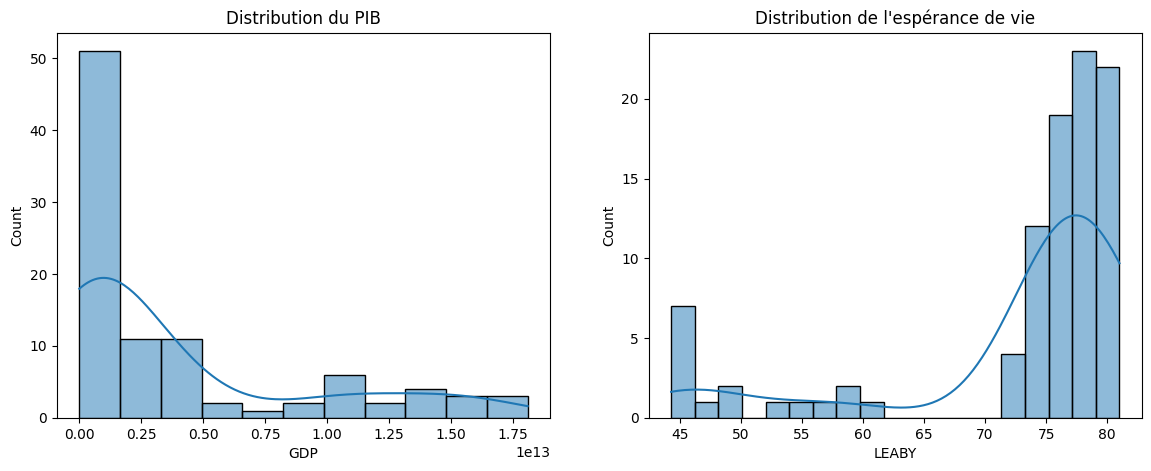

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df.GDP, ax=axes[0], kde=True)
axes[0].set_title("Distribution du PIB")
sns.histplot(df.LEABY, ax=axes[1], kde=True)
axes[1].set_title("Distribution de l'espérance de vie")
plt.show()

**Distributions :** le PIB est très asymétrique (quelques valeurs énormes, surtout États-Unis et Chine),
alors que l'espérance de vie se concentre autour de 75-80 ans, avec un second groupe plus bas (Zimbabwe).

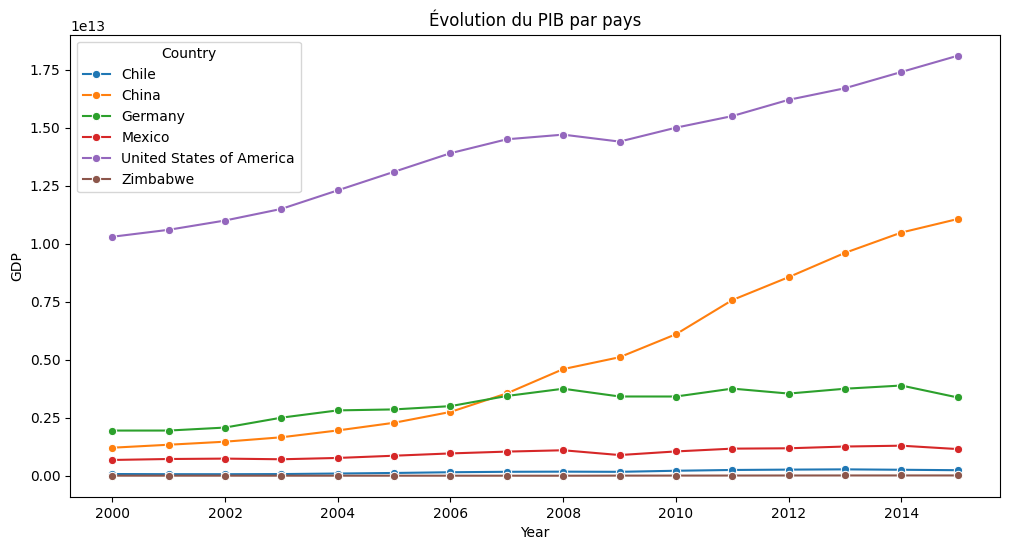

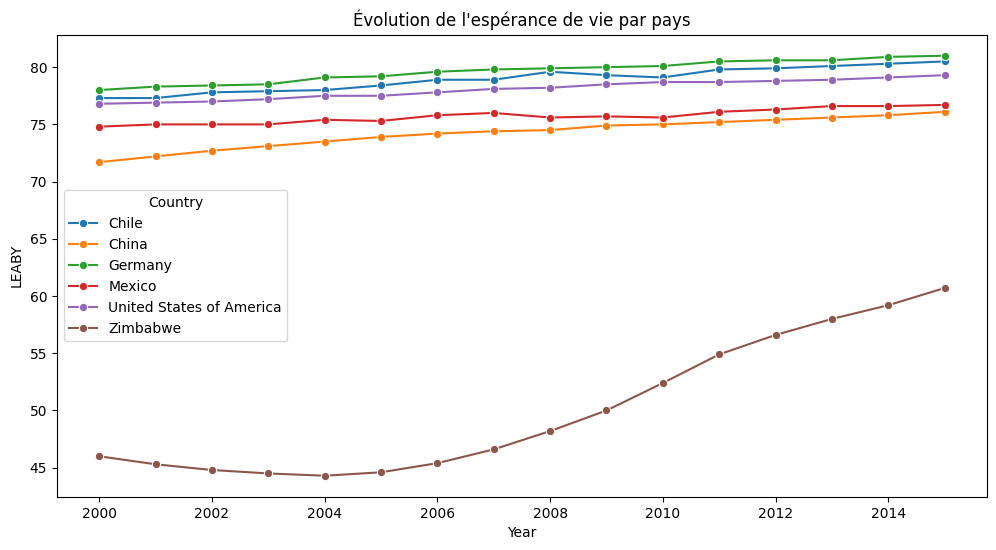

In [5]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x="Year", y="GDP", hue="Country", marker="o")
plt.title("Évolution du PIB par pays")
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x="Year", y="LEABY", hue="Country", marker="o")
plt.title("Évolution de l'espérance de vie par pays")
plt.show()

**Évolution dans le temps :** [pays] a le PIB qui croît le plus vite ; [pays] est stable.
L'espérance de vie [augmente / stagne] dans la plupart des pays ; le Zimbabwe se distingue
par une espérance de vie très basse puis une remontée à partir de [année].

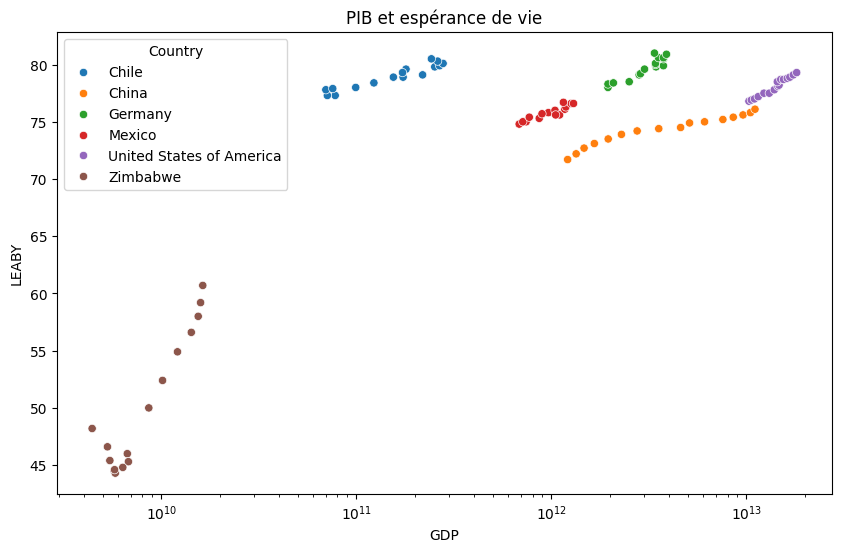

Country
Chile                       0.949877
China                       0.908526
Germany                     0.932699
Mexico                      0.932238
United States of America    0.981709
Zimbabwe                    0.966200
dtype: float64
Corrélation globale : 0.3432067484491559
                          Gain espérance de vie (ans)  Croissance PIB (x)
Country                                                                  
Chile                                             3.2            3.114758
China                                             4.4            9.134189
Germany                                           3.0            1.731126
Mexico                                            1.9            1.685458
United States of America                          2.5            1.757282
Zimbabwe                                         14.7            2.437186


In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="GDP", y="LEABY", hue="Country")
plt.xscale("log")
plt.title("PIB et espérance de vie")
plt.show()

corr = df.groupby("Country")[["GDP", "LEABY"]].apply(lambda d: d["GDP"].corr(d["LEABY"]))
print(corr)
print("Corrélation globale :", df["GDP"].corr(df["LEABY"]))

first = df[df.Year == 2000].set_index("Country")
last = df[df.Year == 2015].set_index("Country")
print(pd.DataFrame({
    "Gain espérance de vie (ans)": last.LEABY - first.LEABY,
    "Croissance PIB (x)": last.GDP / first.GDP
}))

**PIB et espérance de vie :** la relation est [positive], plus marquée pour [pays].
Le Zimbabwe est à part : faible PIB, faible espérance de vie.

## Conclusions
- **Espérance de vie :** elle a augmenté dans les six pays entre 2000 et 2015. Le Zimbabwe progresse le plus (+14,7 ans),
  le Mexique le moins (+1,9 an).
- **PIB :** il a augmenté partout. La Chine se démarque (x9,1), les États-Unis, l'Allemagne et le Mexique croissent plus lentement (x1,7 à x1,8).
- **Corrélation :** forte et positive dans chaque pays (0,91 à 0,98), mais faible au global (0,34), car les niveaux de départ
  diffèrent beaucoup d'un pays à l'autre.
- **Limites :** seulement 6 pays et 16 années. Une corrélation n'est pas une causalité : le PIB et l'espérance de vie
  progressent tous deux avec le temps, et d'autres facteurs jouent (santé publique, VIH au Zimbabwe, éducation).
- **Pistes :** ajouter d'autres pays et d'autres variables (dépenses de santé, éducation), ou tester la relation par régression.

# L'argent fait-il vivre plus longtemps ? PIB et espérance de vie dans 6 pays

## Introduction

Un pays plus riche vit-il plus longtemps ? Pour le savoir, nous avons comparé le PIB et l'espérance de vie à la naissance de six pays : le Chili, la Chine, l'Allemagne, le Mexique, les États-Unis et le Zimbabwe, entre 2000 et 2015.

## Les données

Les données proviennent de la Banque mondiale (PIB) et de l'Organisation mondiale de la Santé (espérance de vie à la naissance). Elles couvrent 16 années pour 6 pays, soit 96 observations, sans valeur manquante.

## Ce que nous avons observé

### 1. L'espérance de vie progresse dans les six pays

Entre 2000 et 2015, le Zimbabwe gagne 14,7 ans, la Chine 4,4 ans, le Chili 3,2 ans, l'Allemagne 3,0 ans, les États-Unis 2,5 ans et le Mexique 1,9 an. Le Zimbabwe part d'un niveau très bas (environ 50 ans en moyenne contre près de 80 ans pour l'Allemagne), ce qui explique son rattrapage spectaculaire.

*(Voir le graphique « Évolution de l'espérance de vie par pays ».)*

### 2. Le PIB augmente aussi, à des rythmes très différents

Le PIB de la Chine est multiplié par 9,1. Celui du Chili est multiplié par 3,1, celui du Zimbabwe par 2,4, et ceux des États-Unis, de l'Allemagne et du Mexique par 1,7 à 1,8 seulement.

*(Voir le graphique « Évolution du PIB par pays ».)*

### 3. Dans chaque pays, plus de PIB va de pair avec plus d'espérance de vie

La corrélation entre PIB et espérance de vie est très forte dans tous les pays : 0,91 en Chine, 0,93 en Allemagne et au Mexique, 0,95 au Chili, 0,97 au Zimbabwe et 0,98 aux États-Unis.

*(Voir le nuage de points « PIB et espérance de vie ».)*

### 4. D'un pays à l'autre, la relation est plus floue

Quand on mélange les six pays, la corrélation globale tombe à 0,34. Les États-Unis ont un PIB bien supérieur à celui du Chili, sans que leurs habitants vivent beaucoup plus longtemps. Le niveau de richesse seul ne suffit donc